In [1]:
# %% [markdown]
# # ML Lab 06 - FBG-based tilt-angle regression (axial + transverse)
# Run top to bottom. Edit ONLY the CONFIG cell. Outputs go to ./results/
#   results/figures/*.png   results/tables/*.csv   results/FBG_Lab6_Report.pdf

In [2]:
# %% 0. CONFIG  (EDIT THESE)
DATA_PATH    = "FBG_dataset.xlsx"                       # the Excel file you downloaded
STUDENT_NAME = "[Your name]"
ROLL_NO      = "[Roll no.]"
CODE_URL     = "[public code link]"   # paste your public GitHub / Colab link here
SEED         = 42
N_SPLITS     = 5      # outer grouped CV folds
INNER_SPLITS = 3      # inner grouped CV folds (hyper-parameter tuning)

In [3]:
# %% 1. IMPORTS & HELPERS
import os, time, warnings, subprocess, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as CK, WhiteKernel
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
np.random.seed(SEED)
sns.set_theme(style="whitegrid", font_scale=0.85)

try:
    get_ipython(); IN_NB = True
except NameError:
    IN_NB = False
    matplotlib.use("Agg")

OUT = "results"; FIG_DIR = f"{OUT}/figures"; TAB_DIR = f"{OUT}/tables"
for d in (OUT, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)
FIGS = {}

def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name + ".png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    FIGS[name] = path
    if IN_NB:
        plt.show()
    plt.close(fig)

def save_tab(df, name):
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"))

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return dict(MAE=mean_absolute_error(y, p), MSE=mse, RMSE=float(np.sqrt(mse)), R2=r2_score(y, p))

In [4]:
# %% 2. LOAD DATA  (Task 1.1)
COLS = ["theta", "FBG1", "FBG2", "dL1", "dL2", "dDiff", "dAvg"]
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Put the Excel file next to this script and set DATA_PATH (looked for {DATA_PATH})")

def load_sheet(path, key):
    xl = pd.ExcelFile(path)
    name = [s for s in xl.sheet_names if key in s.lower()][0]
    raw = xl.parse(name, header=None).iloc[:, :7]          # first row is a measurement, no header
    raw.columns = COLS[:raw.shape[1]]
    return raw.apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True), name

D = {}
for ds, key in (("Axial", "axial"), ("Transverse", "transverse")):
    D[ds], sheet = load_sheet(DATA_PATH, key)
    print(f"{ds}: sheet '{sheet}' -> {D[ds].shape}")

# engineered features (Task 3.1, 3.2) - recomputed from dL1, dL2
for ds, df in D.items():
    df["diff"] = df["dL1"] - df["dL2"]
    df["avg"] = (df["dL1"] + df["dL2"]) / 2
    print(f"{ds}: max |given dDiff - computed| = {np.nanmax(np.abs(df['dDiff'] - df['diff'])):.2e}, "
          f"max |given dAvg - computed| = {np.nanmax(np.abs(df['dAvg'] - df['avg'])):.2e}")
    D[ds] = df.dropna(subset=["theta", "dL1", "dL2"]).reset_index(drop=True)

Axial: sheet 'Experiment axial ' -> (37, 7)
Transverse: sheet 'Experiment transverse ' -> (37, 7)
Axial: max |given dDiff - computed| = 2.27e-10, max |given dAvg - computed| = 0.00e+00
Transverse: max |given dDiff - computed| = 0.00e+00, max |given dAvg - computed| = 0.00e+00



===== Axial =====
Observations: 37 | Features: 6 | Missing: 0 | Duplicates: 2
            mean    median      std       min       max   variance
theta     0.0000     0.000  52.1217   -90.000    90.000  2716.6667
FBG1   1535.2151  1535.216   0.0245  1535.178  1535.248     0.0006
FBG2   1547.3504  1547.349   0.0242  1547.314  1547.385     0.0006
dL1      -0.8919     0.000  24.4583   -38.000    32.000   598.2102
dL2      -0.6216    -2.000  24.2308   -37.000    34.000   587.1306
dDiff    -0.2703     0.000  48.6665   -71.000    68.000  2368.4249
dAvg     -0.7568    -0.500   0.7511    -3.000     0.500     0.5642
Repeated tilt angles:
        n  dL1_mean  dL1_range  dL2_mean  dL2_range
theta                                             
-80    2  -36.0000          0   34.0000          0
-70    2  -33.5000          1   33.0000          0
-60    2  -31.0000          0   29.5000          1
-50    2  -27.0000          0   25.5000          1
-40    2  -22.5000          1   21.0000          0
-30  

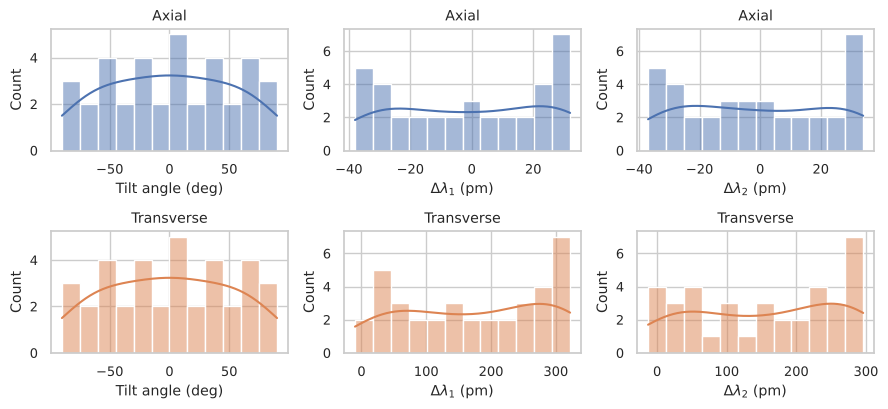

In [5]:
# %% 3. TASK 1 - EXPLORATION
summary = []
for ds, df in D.items():
    base = df[COLS]
    print(f"\n===== {ds} =====")
    print("Observations:", len(df), "| Features:", base.shape[1] - 1, "| Missing:", int(base.isna().sum().sum()),
          "| Duplicates:", int(base.duplicated().sum()))
    summary.append(dict(Dataset=ds, Observations=len(df), Columns=base.shape[1],
                        Missing=int(base.isna().sum().sum()), Duplicates=int(base.duplicated().sum()),
                        Unique_angles=df.theta.round(3).nunique()))
    st = base.describe().T[["mean", "50%", "std", "min", "max"]].rename(columns={"50%": "median"})
    st["variance"] = base.var()
    print(st.round(4))
    save_tab(st, f"descriptive_stats_{ds.lower()}")
    g = df.groupby(df.theta.round(3))
    rep = g.agg(n=("theta", "size"), dL1_mean=("dL1", "mean"), dL1_range=("dL1", lambda s: s.max() - s.min()),
                dL2_mean=("dL2", "mean"), dL2_range=("dL2", lambda s: s.max() - s.min()))
    rep = rep[rep.n > 1]
    print("Repeated tilt angles:\n", rep.round(4))
    save_tab(rep, f"repeated_angles_{ds.lower()}")
save_tab(pd.DataFrame(summary).set_index("Dataset"), "dataset_summary")

fig, axs = plt.subplots(2, 3, figsize=(9, 4.2))
for i, (ds, df) in enumerate(D.items()):
    for j, (c, lab) in enumerate((("theta", "Tilt angle (deg)"), ("dL1", r"$\Delta\lambda_1$ (pm)"), ("dL2", r"$\Delta\lambda_2$ (pm)"))):
        sns.histplot(df[c], bins=12, kde=True, ax=axs[i, j], color=sns.color_palette()[i])
        axs[i, j].set_xlabel(lab); axs[i, j].set_title(f"{ds}")
fig.tight_layout(); save_fig(fig, "fig_task1_distributions")

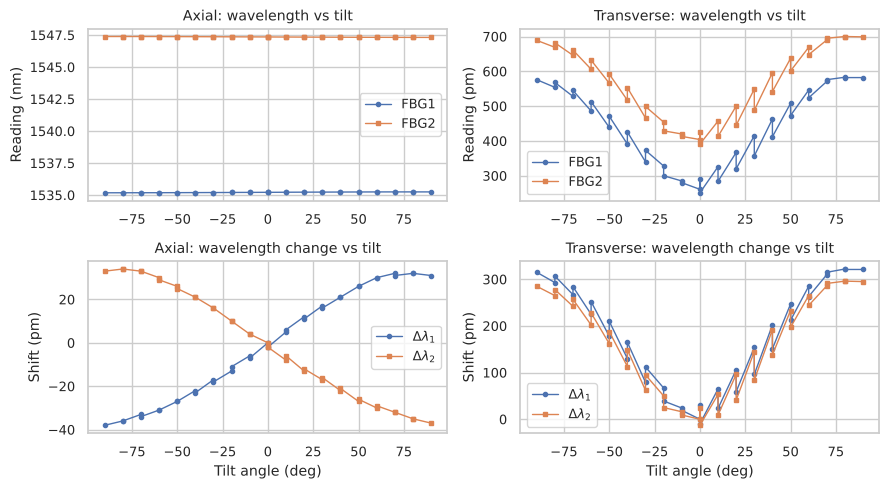

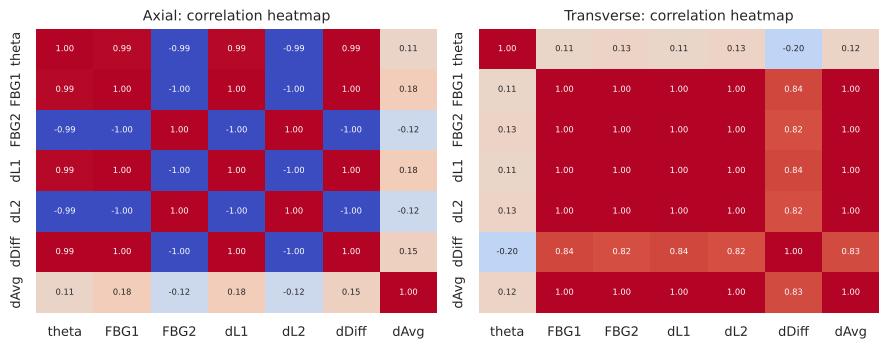

Axial theta: 0 IQR outliers
Axial dL1: 0 IQR outliers
Axial dL2: 0 IQR outliers
Transverse theta: 0 IQR outliers
Transverse dL1: 0 IQR outliers
Transverse dL2: 0 IQR outliers


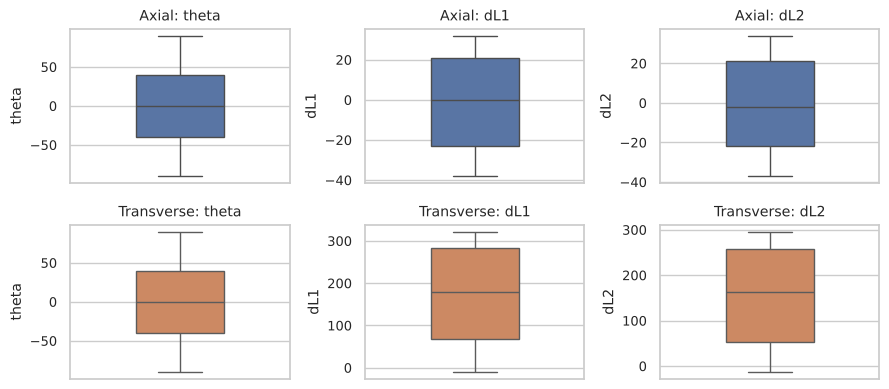

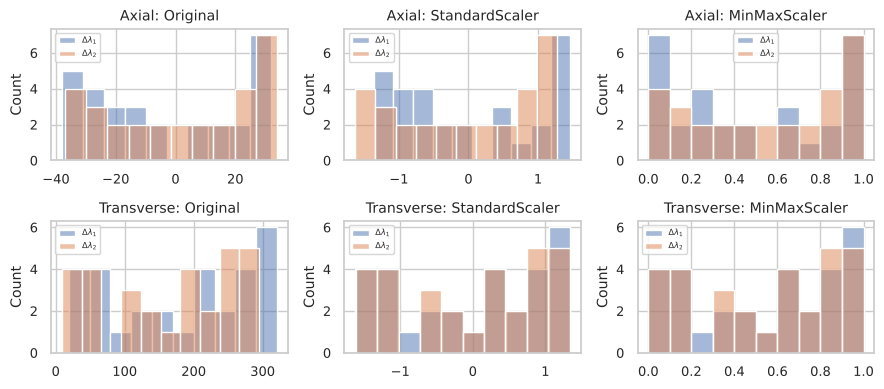

In [6]:
# %% 4. TASK 2 - VISUALISATION & PREPROCESSING
UNIT_RAW = {"Axial": "nm", "Transverse": "pm"}   # units of columns B, C in each sheet (checked against the data)
fig, axs = plt.subplots(2, 2, figsize=(9, 5))
for j, (ds, df) in enumerate(D.items()):
    o = df.sort_values("theta")
    axs[0, j].plot(o.theta, o.FBG1, "o-", ms=3, lw=1, label="FBG1"); axs[0, j].plot(o.theta, o.FBG2, "s-", ms=3, lw=1, label="FBG2")
    axs[0, j].set_title(f"{ds}: wavelength vs tilt"); axs[0, j].set_ylabel(f"Reading ({UNIT_RAW[ds]})"); axs[0, j].legend()
    axs[1, j].plot(o.theta, o.dL1, "o-", ms=3, lw=1, label=r"$\Delta\lambda_1$"); axs[1, j].plot(o.theta, o.dL2, "s-", ms=3, lw=1, label=r"$\Delta\lambda_2$")
    axs[1, j].set_title(f"{ds}: wavelength change vs tilt"); axs[1, j].set_ylabel("Shift (pm)"); axs[1, j].set_xlabel("Tilt angle (deg)"); axs[1, j].legend()
fig.tight_layout(); save_fig(fig, "fig_task2_scatter")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (ds, df) in zip(axs, D.items()):
    sns.heatmap(df[COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax,
                annot_kws={"size": 6}, cbar=False)
    ax.set_title(f"{ds}: correlation heatmap")
fig.tight_layout(); save_fig(fig, "fig_task2_heatmap")

fig, axs = plt.subplots(2, 3, figsize=(9, 4))
for i, (ds, df) in enumerate(D.items()):
    for j, c in enumerate(("theta", "dL1", "dL2")):
        sns.boxplot(y=df[c], ax=axs[i, j], color=sns.color_palette()[i], width=0.4)
        axs[i, j].set_title(f"{ds}: {c}")
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
        print(f"{ds} {c}: {n_out} IQR outliers")
fig.tight_layout(); save_fig(fig, "fig_task2_boxplots")

# scaling comparison (scalers fitted on TRAINING fold only)
fig, axs = plt.subplots(2, 3, figsize=(9, 4))
for i, (ds, df) in enumerate(D.items()):
    X = df[["dL1", "dL2"]].values
    g = pd.factorize(df.theta.round(3))[0]
    tr, _ = next(GroupKFold(N_SPLITS).split(X, groups=g))
    for j, (nm, sc) in enumerate((("Original", None), ("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler()))):
        Xt = X[tr] if sc is None else sc.fit(X[tr]).transform(X[tr])
        for k, lab in enumerate((r"$\Delta\lambda_1$", r"$\Delta\lambda_2$")):
            sns.histplot(Xt[:, k], bins=10, ax=axs[i, j], alpha=.5, label=lab, color=sns.color_palette()[k])
        axs[i, j].set_title(f"{ds}: {nm}"); axs[i, j].legend(fontsize=6)
fig.tight_layout(); save_fig(fig, "fig_task2_scaling")

In [7]:
# %% 5. CV ENGINE (grouped, nested, no leakage)
def make_groups(theta):
    return pd.factorize(np.round(theta, 3))[0]

def fmt_params(p):
    items = []
    for k, v in p.items():
        k = k.split("__")[-1]
        if k == "kernel":
            v = "Matern" if "Matern" in str(v) else "RBF"
        elif isinstance(v, float):
            v = f"{v:.3g}"
        items.append(f"{k}={v}")
    return ", ".join(items)

def outer_cv(est, X, y, g, grid=None):
    oof = np.zeros(len(y)); fit_t, tune_t, pred_t, best, folds, frm = [], [], [], [], [], []
    for tr, te in GroupKFold(N_SPLITS).split(X, y, g):
        if grid:
            gs = GridSearchCV(clone(est), grid, cv=GroupKFold(INNER_SPLITS),
                              scoring="neg_mean_squared_error", n_jobs=1)
            t0 = time.perf_counter(); gs.fit(X[tr], y[tr], groups=g[tr]); tune_t.append(time.perf_counter() - t0)
            model = gs.best_estimator_; fit_t.append(gs.refit_time_); best.append(fmt_params(gs.best_params_))
        else:
            model = clone(est)
            t0 = time.perf_counter(); model.fit(X[tr], y[tr]); dt = time.perf_counter() - t0
            fit_t.append(dt); tune_t.append(dt)
        t0 = time.perf_counter(); oof[te] = model.predict(X[te]); pred_t.append((time.perf_counter() - t0) / len(te) * 1000)
        frm.append(metrics(y[te], oof[te])["RMSE"]); folds.append((tr, te, model))
    r = metrics(y, oof)
    r.update(TrainTime=float(np.mean(fit_t)), TuneTime=float(np.mean(tune_t)), PredMs=float(np.mean(pred_t)),
             RMSE_fold_std=float(np.std(frm)), Params=Counter(best).most_common(1)[0][0] if best else "-",
             oof=oof, folds=folds)
    return r

In [8]:
# %% 6. MODEL DEFINITIONS
class BestSingleFeatureLR(BaseEstimator, RegressorMixin):
    """Simple linear regression: picks the single feature with highest |Pearson r| on the TRAINING data."""
    def fit(self, X, y):
        X = np.asarray(X)
        r = [abs(np.corrcoef(X[:, j], y)[0, 1]) if X[:, j].std() > 0 else 0 for j in range(X.shape[1])]
        self.j_ = int(np.argmax(r)); self.lr_ = LinearRegression().fit(X[:, [self.j_]], y); return self
    def predict(self, X):
        return self.lr_.predict(np.asarray(X)[:, [self.j_]])

def scaled(est):  return Pipeline([("sc", StandardScaler()), ("m", est)])
def poly_reg(deg, est): return Pipeline([("sc", StandardScaler()), ("poly", PolynomialFeatures(deg, include_bias=False)),
                                         ("sc2", StandardScaler()), ("m", est)])
def tt(est): return TransformedTargetRegressor(regressor=scaled(est), transformer=StandardScaler())

K_RBF = CK(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2)) + WhiteKernel(1e-2, (1e-8, 1e0))
K_MAT = CK(1.0, (1e-3, 1e3)) * Matern(1.0, (1e-2, 1e2), nu=1.5) + WhiteKernel(1e-2, (1e-8, 1e0))
def gpr(k): return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=3, random_state=SEED)
ALPHAS = list(np.logspace(-6, 1, 15))

# name -> (estimator, grid, feature set, group)
MAIN = {
    "Simple LR":        (BestSingleFeatureLR(), None, "ALL", "Statistical"),
    "Multiple LR":      (scaled(LinearRegression()), None, "F1", "Statistical"),
    "Polynomial (deg 2)": (poly_reg(2, LinearRegression()), None, "F1", "Statistical"),
    "Polynomial (deg 3)": (poly_reg(3, LinearRegression()), None, "F1", "Statistical"),
    # regularised models work on polynomial features (degree 2 or 3 and alpha are tuned in the inner CV)
    "Ridge":            (poly_reg(3, Ridge()), {"poly__degree": [2, 3], "m__alpha": ALPHAS}, "F1", "Statistical"),
    "Lasso":            (poly_reg(3, Lasso(max_iter=100000)), {"poly__degree": [2, 3], "m__alpha": ALPHAS}, "F1", "Statistical"),
    "Elastic Net":      (poly_reg(3, ElasticNet(max_iter=100000)), {"poly__degree": [2, 3], "m__alpha": ALPHAS, "m__l1_ratio": [0.2, 0.5, 0.8]}, "F1", "Statistical"),
    "SVR":              (tt(SVR()), {"regressor__m__kernel": ["linear", "rbf"], "regressor__m__C": [1, 10, 100]}, "F1", "ML"),
    "Decision Tree":    (DecisionTreeRegressor(random_state=SEED), {"max_depth": [2, 3, 5]}, "F1", "ML"),
    "Random Forest":    (RandomForestRegressor(random_state=SEED), {"n_estimators": [50, 100]}, "F1", "ML"),
    "KNN":              (scaled(KNeighborsRegressor()), {"m__n_neighbors": [3, 5, 7]}, "F1", "ML"),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=100, random_state=SEED), {"learning_rate": [0.01, 0.1]}, "F1", "ML"),
    "GPR":              (scaled(gpr(K_RBF)), {"m__kernel": [K_RBF, K_MAT]}, "F1", "ML"),
}
LINEAR = {"Simple LR", "Multiple LR"}   # linear in the raw inputs

FS, Y, G = {}, {}, {}
for ds, df in D.items():
    FS[ds] = {"F1": df[["dL1", "dL2"]].values, "F2": df[["diff"]].values, "F3": df[["avg"]].values,
              "F4": df[["diff", "avg"]].values, "ALL": df[["dL1", "dL2", "diff", "avg"]].values}
    Y[ds] = df["theta"].values; G[ds] = make_groups(df["theta"].values)

In [9]:
# %% 7. TASK 3 - FEATURE ENGINEERING / SELECTION
corr_rows = []
for c, lab in (("dL1", "dL1"), ("dL2", "dL2"), ("diff", "dL_diff"), ("avg", "dL_avg")):
    row = {"Feature": lab}
    for ds, df in D.items():
        r, p = pearsonr(df[c], df.theta); row[f"{ds} r"] = r; row[f"{ds} p"] = p
    corr_rows.append(row)
CORR = pd.DataFrame(corr_rows).set_index("Feature"); print(CORR.round(4)); save_tab(CORR, "pearson_correlations")

FCFG = {"F1": "F1: dL1, dL2", "F2": "F2: diff", "F3": "F3: avg", "F4": "F4: diff, avg"}
fm = {"MLR": scaled(LinearRegression()), "Poly2": poly_reg(2, LinearRegression()),
      "RF": RandomForestRegressor(n_estimators=100, random_state=SEED)}
rows = []
for f, lab in FCFG.items():
    row = {"Feature set": lab}
    for ds in D:
        for mn, m in fm.items():
            row[f"{ds[:3]} {mn} RMSE"] = outer_cv(m, FS[ds][f], Y[ds], G[ds])["RMSE"]
    rows.append(row)
FEAT = pd.DataFrame(rows).set_index("Feature set")
BEST_FEAT = {ds: FEAT[[c for c in FEAT.columns if c.startswith(ds[:3])]].mean(axis=1).idxmin() for ds in D}
print(FEAT.round(4)); print("Most informative feature set:", BEST_FEAT); save_tab(FEAT, "feature_set_comparison")

         Axial r  Axial p  Transverse r  Transverse p
Feature                                              
dL1       0.9917   0.0000        0.1082        0.5237
dL2      -0.9939   0.0000        0.1288        0.4473
dL_diff   0.9932   0.0000       -0.2007        0.2336
dL_avg    0.1135   0.5035        0.1183        0.4857


               Axi MLR RMSE  Axi Poly2 RMSE  Axi RF RMSE  Tra MLR RMSE  \
Feature set                                                              
F1: dL1, dL2         6.5276          4.9384       6.4818       48.5053   
F2: diff             6.1845          6.5564       7.2360       54.7718   
F3: avg             56.8230         56.5646      58.5287       53.6371   
F4: diff, avg        6.5276          4.9384       7.6716       48.5053   

               Tra Poly2 RMSE  Tra RF RMSE  
Feature set                                 
F1: dL1, dL2          31.8300      54.1733  
F2: diff              54.1372      60.7481  
F3: avg               52.8340      54.5459  
F4: diff, avg         31.8300      38.4340  
Most informative feature set: {'Axial': 'F1: dL1, dL2', 'Transverse': 'F4: diff, avg'}


In [10]:
# %% 8. TASKS 4, 5, 6 - MAIN NESTED GROUPED-CV COMPARISON
RES = {ds: {} for ds in D}
for ds in D:
    for name, (est, grid, fs, grp) in MAIN.items():
        RES[ds][name] = outer_cv(est, FS[ds][fs], Y[ds], G[ds], grid)
        r = RES[ds][name]; print(f"{ds:10s} {name:20s} RMSE={r['RMSE']:.4f} R2={r['R2']:.4f} [{r['Params']}]")

R = {}
for ds in D:
    t = pd.DataFrame({n: {k: v for k, v in r.items() if k in ("MAE", "MSE", "RMSE", "R2", "TrainTime", "TuneTime", "PredMs", "RMSE_fold_std", "Params")}
                      for n, r in RES[ds].items()}).T
    t["Group"] = [MAIN[n][3] for n in t.index]
    for c in ("MAE", "MSE", "RMSE", "R2", "TrainTime", "TuneTime", "PredMs", "RMSE_fold_std"):
        t[c] = t[c].astype(float)
    R[ds] = t; save_tab(t, f"results_{ds.lower()}")
STAT = [n for n in MAIN if MAIN[n][3] == "Statistical"]; ML = [n for n in MAIN if MAIN[n][3] == "ML"]
BEST_STAT = {ds: R[ds].loc[STAT, "RMSE"].idxmin() for ds in D}
BEST_ML = {ds: R[ds].loc[ML, "RMSE"].idxmin() for ds in D}
print("Best statistical:", BEST_STAT, "\nBest ML:", BEST_ML)

# per-angle error analysis of the best ML model (Task 5.4)
for ds in D:
    o = RES[ds][BEST_ML[ds]]["oof"]
    pa = pd.DataFrame({"theta": Y[ds], "pred": o, "abs_err": np.abs(Y[ds] - o)}).sort_values("theta")
    save_tab(pa.set_index("theta"), f"per_angle_error_{ds.lower()}")
    print(ds, "worst angles:", pa.nlargest(3, "abs_err")[["theta", "abs_err"]].values.round(3).tolist())

Axial      Simple LR            RMSE=6.2443 R2=0.9852 [-]
Axial      Multiple LR          RMSE=6.5276 R2=0.9839 [-]
Axial      Polynomial (deg 2)   RMSE=4.9384 R2=0.9908 [-]
Axial      Polynomial (deg 3)   RMSE=4.3516 R2=0.9928 [-]


Axial      Ridge                RMSE=2.4048 R2=0.9978 [alpha=0.316, degree=3]


Axial      Lasso                RMSE=2.3221 R2=0.9980 [alpha=0.0316, degree=3]


Axial      Elastic Net          RMSE=2.3154 R2=0.9980 [alpha=0.0316, l1_ratio=0.2, degree=3]


Axial      SVR                  RMSE=6.1107 R2=0.9859 [C=1, kernel=RBF]
Axial      Decision Tree        RMSE=10.0000 R2=0.9622 [max_depth=5]


...

Transverse Elastic Net          RMSE=23.1969 R2=0.7964 [alpha=1e-06, l1_ratio=0.8, degree=3]


Transverse SVR                  RMSE=50.9536 R2=0.0178 [C=100, kernel=RBF]
Transverse Decision Tree        RMSE=63.7853 R2=-0.5392 [max_depth=2]


Transverse Random Forest        RMSE=54.1733 R2=-0.1103 [n_estimators=100]
Transverse KNN                  RMSE=54.0935 R2=-0.1070 [n_neighbors=7]


Transverse Gradient Boosting    RMSE=53.3333 R2=-0.0761 [learning_rate=0.01]


Transverse GPR                  RMSE=52.7713 R2=-0.0536 [kernel=Matern]
Best statistical: {'Axial': 'Elastic Net', 'Transverse': 'Elastic Net'} 
Best ML: {'Axial': 'GPR', 'Transverse': 'SVR'}
Axial worst angles: [[-90.0, 4.984], [50.0, 4.966], [90.0, 4.226]]
Transverse worst angles: [[80.0, 130.151], [80.0, 123.033], [-90.0, 111.325]]


In [11]:
# %% 9. HYPER-PARAMETER STUDY (fixed values, same grouped CV, Tasks 4d / 5.2)
HP = []
for deg in (1, 2, 3):
    HP.append(("Polynomial", f"degree={deg}", poly_reg(deg, LinearRegression())))
for a in (0.01, 0.1, 1.0):
    HP.append(("Ridge (poly3)", f"alpha={a}", poly_reg(3, Ridge(alpha=a))))
    HP.append(("Lasso (poly3)", f"alpha={a}", poly_reg(3, Lasso(alpha=a, max_iter=100000))))
    HP.append(("Elastic Net (poly3)", f"alpha={a}, l1=0.5", poly_reg(3, ElasticNet(alpha=a, l1_ratio=0.5, max_iter=100000))))
for k in ("linear", "rbf"):
    HP.append(("SVR", f"kernel={k}, C=10", tt(SVR(kernel=k, C=10))))
for d_ in (2, 3, 5):
    HP.append(("Decision Tree", f"max_depth={d_}", DecisionTreeRegressor(max_depth=d_, random_state=SEED)))
for n_ in (50, 100):
    HP.append(("Random Forest", f"n_trees={n_}", RandomForestRegressor(n_estimators=n_, random_state=SEED)))
for k in (3, 5, 7):
    HP.append(("KNN", f"k={k}", scaled(KNeighborsRegressor(n_neighbors=k))))
for lr in (0.01, 0.1):
    HP.append(("Gradient Boosting", f"lr={lr}", GradientBoostingRegressor(learning_rate=lr, n_estimators=100, random_state=SEED)))
HP.append(("GPR", "RBF kernel", scaled(gpr(K_RBF)))); HP.append(("GPR", "Matern kernel", scaled(gpr(K_MAT))))

rows = []
for grp, lab, est in HP:
    row = {"Model": grp, "Setting": lab}
    for ds in D:
        r = outer_cv(est, FS[ds]["F1"], Y[ds], G[ds])
        row[f"{ds[:3]} MAE"] = r["MAE"]; row[f"{ds[:3]} RMSE"] = r["RMSE"]; row[f"{ds[:3]} R2"] = r["R2"]
    rows.append(row)
HPT = pd.DataFrame(rows); save_tab(HPT.set_index(["Model", "Setting"]), "hyperparameter_study"); print(HPT.round(4).to_string())

                  Model              Setting  Axi MAE  Axi RMSE  Axi R2  Tra MAE  Tra RMSE  Tra R2
0            Polynomial             degree=1   5.0068    6.5276  0.9839  40.8937   48.5053  0.1099
1            Polynomial             degree=2   4.3583    4.9384  0.9908  25.3350   31.8300  0.6167
2            Polynomial             degree=3   2.7833    4.3516  0.9928  20.9268   29.9488  0.6607
3         Ridge (poly3)           alpha=0.01   1.6544    2.0675  0.9984  21.2435   25.7348  0.7494
4         Lasso (poly3)           alpha=0.01   1.6404    2.1185  0.9983  20.5701   23.6652  0.7881
5   Elastic Net (poly3)   alpha=0.01, l1=0.5   1.7643    2.4908  0.9977  36.2937   42.2666  0.3241
6         Ridge (poly3)            alpha=0.1   1.7109    2.3361  0.9979  33.6537   39.2479  0.4172
7         Lasso (poly3)            alpha=0.1   2.0407    3.4970  0.9954  21.2353   24.8924  0.7656
8   Elastic Net (poly3)    alpha=0.1, l1=0.5   3.1283    3.8316  0.9944  43.1505   51.0300  0.0148
9         

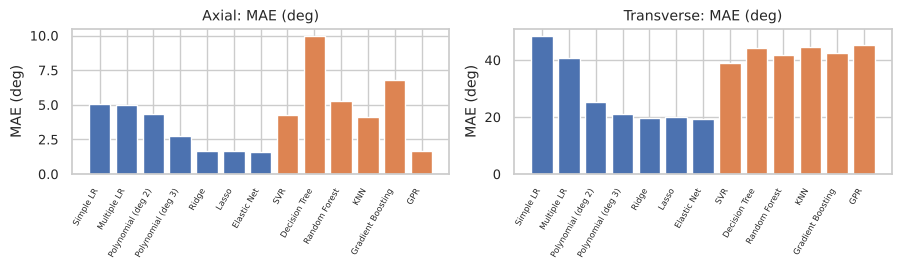

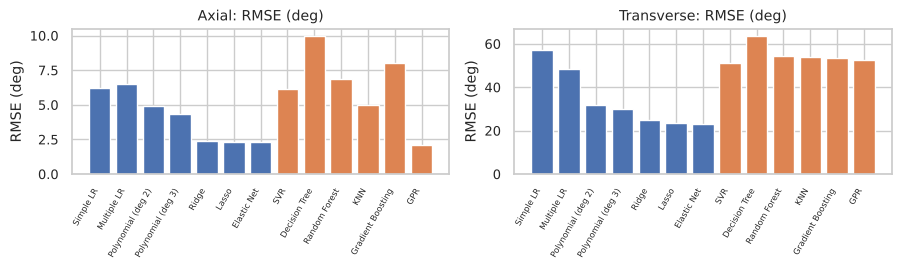

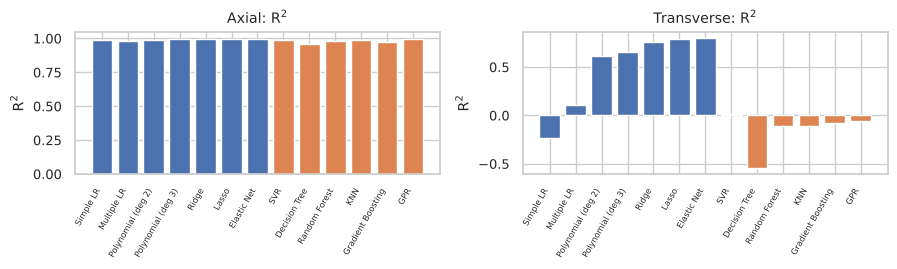

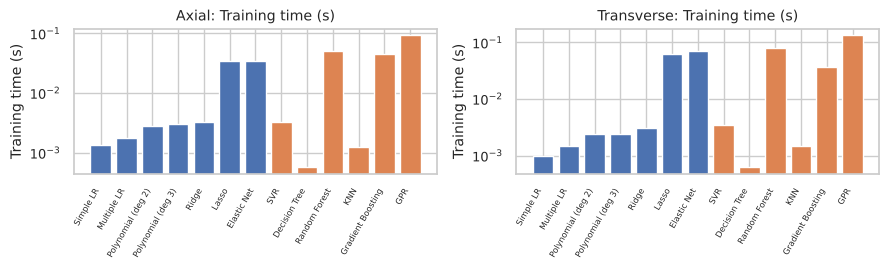

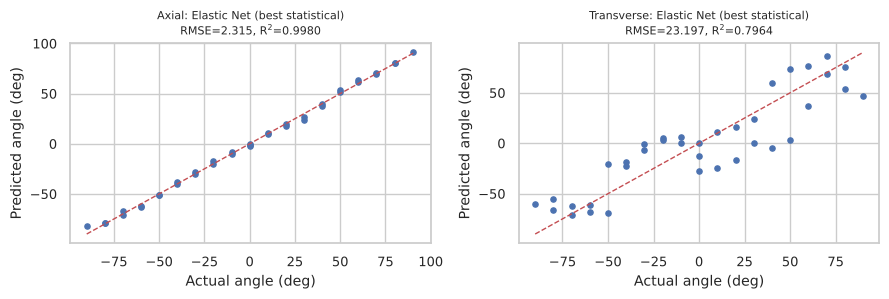

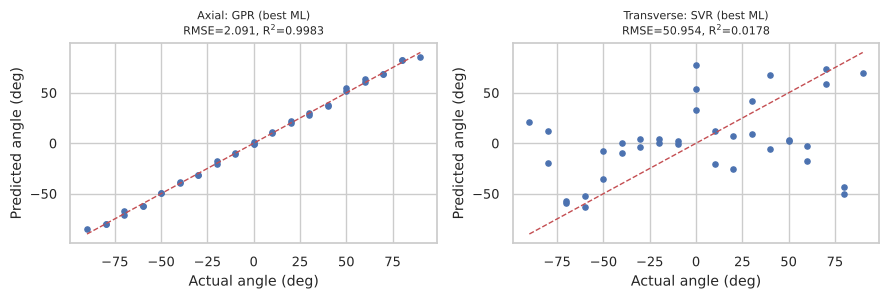

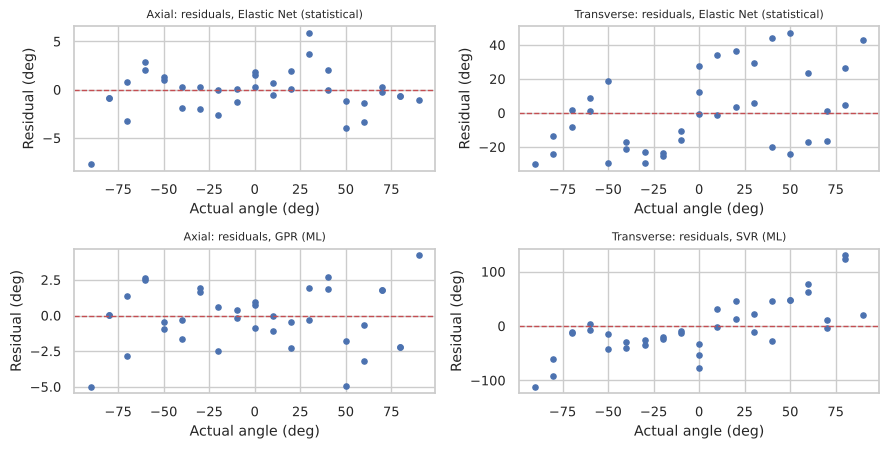

In [12]:
# %% 10. REQUIRED GRAPHS (Task 6)
PAL = {"Statistical": "#4C72B0", "ML": "#DD8452"}
def bar_fig(col, ylabel, name, log=False):
    fig, axs = plt.subplots(1, 2, figsize=(9, 2.8))
    for ax, ds in zip(axs, D):
        t = R[ds]; ax.bar(range(len(t)), t[col], color=[PAL[g] for g in t.Group])
        ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=60, ha="right", fontsize=6)
        ax.set_title(f"{ds}: {ylabel}"); ax.set_ylabel(ylabel)
        if log: ax.set_yscale("log")
    fig.tight_layout(); save_fig(fig, name)
bar_fig("MAE", "MAE (deg)", "fig1_mae"); bar_fig("RMSE", "RMSE (deg)", "fig2_rmse"); bar_fig("R2", "R$^2$", "fig3_r2")
bar_fig("TrainTime", "Training time (s)", "fig7_training_time", log=True)

def avp_fig(best, name, label):
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.1))
    for ax, ds in zip(axs, D):
        m = best[ds]; o = RES[ds][m]["oof"]; lim = [min(Y[ds].min(), o.min()), max(Y[ds].max(), o.max())]
        ax.scatter(Y[ds], o, s=14); ax.plot(lim, lim, "r--", lw=1)
        ax.set_title(f"{ds}: {m} ({label})\nRMSE={RES[ds][m]['RMSE']:.3f}, R$^2$={RES[ds][m]['R2']:.4f}", fontsize=8)
        ax.set_xlabel("Actual angle (deg)"); ax.set_ylabel("Predicted angle (deg)")
    fig.tight_layout(); save_fig(fig, name)
avp_fig(BEST_STAT, "fig4_avp_best_statistical", "best statistical"); avp_fig(BEST_ML, "fig5_avp_best_ml", "best ML")

fig, axs = plt.subplots(2, 2, figsize=(9, 4.6))
for i, (best, lab) in enumerate(((BEST_STAT, "statistical"), (BEST_ML, "ML"))):
    for j, ds in enumerate(D):
        m = best[ds]; res = Y[ds] - RES[ds][m]["oof"]
        axs[i, j].scatter(Y[ds], res, s=14); axs[i, j].axhline(0, color="r", ls="--", lw=1)
        axs[i, j].set_title(f"{ds}: residuals, {m} ({lab})", fontsize=8)
        axs[i, j].set_xlabel("Actual angle (deg)"); axs[i, j].set_ylabel("Residual (deg)")
fig.tight_layout(); save_fig(fig, "fig6_residuals")

                    Signed_MAE  Signed_RMSE  Signed_R2  Abs_MAE  Abs_RMSE  \
Model                                                                       
Simple LR              48.5853      57.0133    -0.2297   5.4090    6.4664   
Multiple LR            40.8937      48.5053     0.1099   4.1846    4.9888   
Polynomial (deg 2)     25.3350      31.8300     0.6167   3.9893    4.9589   
Polynomial (deg 3)     20.9268      29.9488     0.6607   5.4518    7.7149   
Ridge                  19.7713      25.0207     0.7632   3.8146    4.7531   
Lasso                  20.1447      23.4302     0.7923   3.7791    4.6810   
Elastic Net            19.4721      23.1969     0.7964   3.7561    4.6997   
SVR                    38.8242      50.9536     0.0178   4.1221    4.8871   
Decision Tree          44.1085      63.7853    -0.5392  10.5856   11.6578   
Random Forest          41.7297      54.1733    -0.1103   8.8514   10.3151   
KNN                    44.5277      54.0935    -0.1070   7.5135    9.1848   

sign accuracy (chance = 0.50): {'Logistic regression': 0.7058823529411765, 'Random forest': 0.5882352941176471}
mean |dL1(+th) - dL1(-th)| = 27.3 pm | mean repeat range of dL1: {'Axial': 0.7, 'Transverse': 28.9}


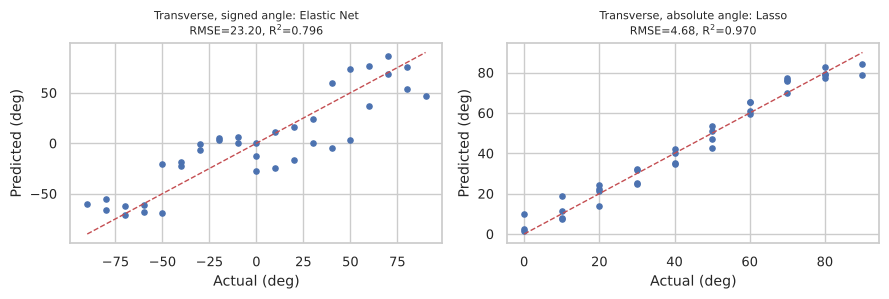

In [13]:
# %% 11. ADVANCED TASK C - signed vs absolute tilt (transverse data)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
ds = "Transverse"; y_sg = Y[ds]; y_ab = np.abs(y_sg)
RES_ABS, rows = {}, []
for name, (est, grid, fs, grp) in MAIN.items():
    RES_ABS[name] = outer_cv(est, FS[ds][fs], y_ab, G[ds], grid)       # same folds as the signed run
    rows.append(dict(Model=name, Signed_MAE=R[ds].loc[name, "MAE"], Signed_RMSE=R[ds].loc[name, "RMSE"], Signed_R2=R[ds].loc[name, "R2"],
                     Abs_MAE=RES_ABS[name]["MAE"], Abs_RMSE=RES_ABS[name]["RMSE"], Abs_R2=RES_ABS[name]["R2"]))
TC = pd.DataFrame(rows).set_index("Model"); save_tab(TC, "taskC_signed_vs_abs"); print(TC.round(4))
BEST_SG = TC.Signed_RMSE.idxmin(); BEST_AB = TC.Abs_RMSE.idxmin()
TCCORR = pd.DataFrame({"r with theta": [pearsonr(D[ds][c], y_sg)[0] for c in ("dL1", "dL2", "diff", "avg")],
                       "r with |theta|": [pearsonr(D[ds][c], y_ab)[0] for c in ("dL1", "dL2", "diff", "avg")]}, index=["dL1", "dL2", "diff", "avg"])
save_tab(TCCORR, "taskC_pearson"); print(TCCORR.round(4))

# can the two FBG readings tell +theta from -theta?  (theta = 0 left out)
nz = y_sg != 0; Xc = FS[ds]["ALL"][nz]; yc = (y_sg[nz] > 0).astype(int); gc = G[ds][nz]; SIGN_ACC = {}
for nm, clf in (("Logistic regression", scaled(LogisticRegression(max_iter=1000))), ("Random forest", RandomForestClassifier(100, random_state=SEED))):
    pr = np.zeros(len(yc), int)
    for tr, te in GroupKFold(N_SPLITS).split(Xc, yc, gc):
        pr[te] = clone(clf).fit(Xc[tr], yc[tr]).predict(Xc[te])
    SIGN_ACC[nm] = float((pr == yc).mean())
print("sign accuracy (chance = %.2f):" % max(yc.mean(), 1 - yc.mean()), SIGN_ACC)

# size of the +theta / -theta difference compared with the repeat (up/down) scatter
dfT = D[ds]; pos = dfT[dfT.theta > 0].groupby(dfT.theta.round(3)).dL1.mean(); neg = dfT[dfT.theta < 0].groupby((-dfT.theta).round(3)).dL1.mean()
PAIR_DIFF = float((pos - neg).dropna().abs().mean())
REPEAT_RANGE = {k: float(pd.read_csv(f"{TAB_DIR}/repeated_angles_{k.lower()}.csv").dL1_range.mean()) for k in D}
print("mean |dL1(+th) - dL1(-th)| =", round(PAIR_DIFF, 1), "pm | mean repeat range of dL1:", {k: round(v, 1) for k, v in REPEAT_RANGE.items()})

fig, axs = plt.subplots(1, 2, figsize=(9, 3.1))
for ax, (m, o, yy, lab) in zip(axs, ((BEST_SG, RES[ds][BEST_SG]["oof"], y_sg, "signed angle"), (BEST_AB, RES_ABS[BEST_AB]["oof"], y_ab, "absolute angle"))):
    lim = [min(yy.min(), o.min()), max(yy.max(), o.max())]; ax.scatter(yy, o, s=14); ax.plot(lim, lim, "r--", lw=1)
    r_ = metrics(yy, o); ax.set_title(f"Transverse, {lab}: {m}\nRMSE={r_['RMSE']:.2f}, R$^2$={r_['R2']:.3f}", fontsize=8)
    ax.set_xlabel("Actual (deg)"); ax.set_ylabel("Predicted (deg)")
fig.tight_layout(); save_fig(fig, "fig_advC_signed_vs_abs")

In [14]:
# %% 12. REPORT TEXT (written after looking at the results; numbers are filled in from the tables)
A, T = R["Axial"], R["Transverse"]
DUPS = {x["Dataset"]: x["Duplicates"] for x in summary}
def v(df, m, c="RMSE", d=2): return f"{df.loc[m, c]:.{d}f}"
fe = lambda k, c: f"{FEAT.loc[k, c]:.2f}"

METHOD = (
    f"We used the two experimental sheets (axial and transverse, {len(D['Axial'])} readings each, 7 columns, no missing values) and nothing from the theoretical sheet. "
    f"The axial sheet has {DUPS['Axial']} exact duplicate rows (same angle, same readings, up-sweep and down-sweep). We kept them because they are genuine repeat measurements. "
    "The two datasets are modelled separately. Input is X = [Δλ1, Δλ2] and the target is the tilt angle θ in degrees. "
    "The sheets give no unit for Δλ; from the axial wavelengths (1535.222 − 1535.216 = 0.006 nm, and the sheet shows 6) the changes are in pm. "
    "Δλdiff and Δλavg were recomputed from Δλ1 and Δλ2 and match the sheet values. "
    f"<b>Validation.</b> Every model is scored with 5-fold grouped cross-validation, where all readings taken at the same tilt angle go into the same fold (random seed {SEED}). "
    f"Hyper-parameters are chosen inside each training fold by an inner {INNER_SPLITS}-fold grouped grid search, so the test fold is never used for tuning. "
    "Scalers sit inside the model pipelines and are fitted on the training fold only. MAE, MSE, RMSE and R² are computed on the pooled out-of-fold predictions. "
    "Training time is the mean time to refit the chosen model on one training fold (tuning not counted). "
    "Ridge, Lasso and Elastic Net are run on polynomial features (degree 2 or 3, picked by the inner search) because on two raw inputs they would just copy plain linear regression. "
    "Simple linear regression picks the single best of Δλ1, Δλ2, Δλdiff, Δλavg on each training fold."
)
ALGO = ("<b>Algorithm (Ridge, nested grouped CV).</b> 1) Read the sheet, build X = [Δλ1, Δλ2], y = θ, group id = angle. "
        "2) Split into 5 folds by group. 3) For each fold: standardise the training inputs, expand to polynomial features, standardise again. "
        "4) For every degree in {2, 3} and α in the grid, run the inner 3-fold grouped CV and record the mean squared error. "
        "5) Keep the (degree, α) with the smallest inner error and refit Ridge on the whole training part: w = (ΦᵀΦ + αI)⁻¹Φᵀy. "
        "6) Transform the test fold with the training scalers, predict θ̂ and store it. "
        "7) After 5 folds, compute MAE, MSE, RMSE and R² on all stored predictions. 8) Repeat for the transverse data and for the other models.")

if not (BEST_STAT["Axial"] == BEST_STAT["Transverse"] == "Elastic Net" and BEST_ML["Axial"] == "GPR" and BEST_ML["Transverse"] == "SVR"):
    print("NOTE: the best models differ from the ones the report text was written for - re-read Section 2 and 6 of the PDF and edit the text.")
RES_NOTE = (f"Axial: GPR has the lowest RMSE ({v(A,'GPR')}°), followed by Elastic Net, Lasso and Ridge on cubic features (about {v(A,'Elastic Net')}–{v(A,'Ridge')}°). Plain linear regression is at {v(A,'Multiple LR')}°. "
            f"Transverse (signed θ): Elastic Net is best ({v(T,'Elastic Net')}°, R² {v(T,'Elastic Net','R2',3)}); most other models have R² near or below zero (see Section 5).")

DISC = [
 ("1. Best traditional statistical model?",
  f"Elastic Net on cubic polynomial features has the lowest RMSE on both axes: axial {v(A,'Elastic Net')}° (R² {v(A,'Elastic Net','R2',4)}), transverse {v(T,'Elastic Net')}° (R² {v(T,'Elastic Net','R2',3)}). "
  f"On the axial data Lasso ({v(A,'Lasso')}°) and Ridge ({v(A,'Ridge')}°) are practically tied with it, so the choice among the three matters little. "
  f"For comparison, plain linear regression gave {v(A,'Simple LR')}° (simple) and {v(A,'Multiple LR')}° (multiple), and unpenalised polynomials gave {v(A,'Polynomial (deg 2)')}° (degree 2) and {v(A,'Polynomial (deg 3)')}° (degree 3). "
  "Adding the penalty to the cubic model almost halved the error again."),
 ("2. ML model with the lowest RMSE?",
  f"Axial: GPR, {v(A,'GPR')}° (R² {v(A,'GPR','R2',4)}). Transverse: SVR has the lowest RMSE of the ML group ({v(T,'SVR')}°) but its R² is only {v(T,'SVR','R2',3)}, so it explains almost none of the signed angle. "
  "For the transverse data the number says more about the target than about the model (see Q6)."),
 ("3. Do non-linear models beat linear ones?",
  f"Only some of them. On the axial data Ridge, Lasso and Elastic Net on polynomial features and GPR ({v(A,'GPR')}–{v(A,'Ridge')}°) were roughly three times better than linear regression ({v(A,'Simple LR')}–{v(A,'Multiple LR')}°), and KNN ({v(A,'KNN')}°) also beat it. "
  f"Random forest ({v(A,'Random Forest')}°), gradient boosting ({v(A,'Gradient Boosting')}°) and the decision tree ({v(A,'Decision Tree')}°) were worse than a straight line. "
  "The tree is exactly 10° off on every test point: all angles are multiples of 10° and a tree can only return an angle it has seen, so for a held-out angle it returns a neighbour. "
  "Tree-type models also cannot go beyond the training range, which hurts at ±90°."),
 ("4. How does feature selection affect the results?",
  f"A lot when a feature carries no information. On the axial data Δλavg alone (F3) gives RMSE {fe('F3: avg','Axi MLR RMSE')}° with MLR, because Δλ1 and Δλ2 move in opposite directions and their average stays near zero (r = {CORR.loc['dL_avg','Axial r']:.2f}). "
  f"Δλdiff alone (F2) is enough for a linear fit ({fe('F2: diff','Axi MLR RMSE')}°, about the same as using both inputs, {fe('F1: dL1, dL2','Axi MLR RMSE')}°). "
  f"F4 is just a re-mixing of F1, so MLR and the polynomial give identical numbers for them, while the random forest does not ({fe('F4: diff, avg','Axi RF RMSE')}° vs {fe('F1: dL1, dL2','Axi RF RMSE')}°). "
  f"The most informative set for axial is F1 (best polynomial result {fe('F1: dL1, dL2','Axi Poly2 RMSE')}°). For the transverse data every feature has a Pearson r of at most 0.2 (in size) with signed θ but 0.90 to 0.97 with |θ| (Table 6), so the features are fine and the signed target is the problem."),
 ("5. Does more complexity always help?",
  f"No. Axial RMSE falls from {v(A,'Multiple LR')}° (linear) to {v(A,'Polynomial (deg 2)')}° (degree 2) to {v(A,'Polynomial (deg 3)')}° (degree 3), but the random forest, boosting and the deep tree are worse than linear regression. "
  f"GPR is the most flexible model and beats Ridge by only {A.loc['Ridge','RMSE']-A.loc['GPR','RMSE']:.1f}° ({A.loc['GPR','RMSE']:.2f}° against {A.loc['Ridge','RMSE']:.2f}°), while it trains about {A.loc['GPR','TrainTime']/A.loc['Ridge','TrainTime']:.0f} times slower. "
  f"The unregularised cubic model on the transverse data has the largest fold-to-fold spread of the statistical models ({v(T,'Polynomial (deg 3)','RMSE_fold_std')}° against {v(T,'Ridge','RMSE_fold_std')}° for Ridge), which is what overfitting looks like with 37 points."),
 ("6. Why do axial and transverse errors differ?",
  f"Two reasons that show up directly in the data. (a) The transverse readings go up for both positive and negative tilt, so the curves are V-shaped in θ. Signed θ is then not a function of the two readings. "
  f"That is why Δλ1 has r = {TCCORR.loc['dL1','r with theta']:.2f} with θ but {TCCORR.loc['dL1','r with |theta|']:.2f} with |θ|. In the axial data the two gratings move in opposite directions, so the sign is clear. "
  f"(b) The transverse sensor shows much more hysteresis. Repeated readings at the same angle differ by {REPEAT_RANGE['Transverse']:.1f} pm on average in Δλ1, against {REPEAT_RANGE['Axial']:.1f} pm for the axial sensor. "
  f"On the axial sensor Δλ1 flattens out above about 70°, but that costs far less than the hysteresis does on the transverse one."),
 ("7. Which model for real-time monitoring?",
  f"For the axial direction: Ridge regression on cubic polynomial features (Elastic Net is a hair better at {v(A,'Elastic Net')}°, but needs a longer tuning run). Its RMSE of {v(A,'Ridge')}° is {A.loc['Ridge','RMSE']-A.loc['GPR','RMSE']:.1f}° above GPR ({v(A,'GPR')}°), it refits in about {A.loc['Ridge','TrainTime']*1000:.0f} ms, "
  f"predicts in about {A.loc['Ridge','PredMs']:.2f} ms per reading and has only nine coefficients, so it is easy to recalibrate and to run on a small controller. GPR is the better choice only if that last {A.loc['Ridge','RMSE']-A.loc['GPR','RMSE']:.1f}° matters and the extra training time is acceptable. "
  f"For the transverse direction I would not deploy a signed-angle model. Predicting |θ| gives {v(TC.rename(columns={'Abs_RMSE':'RMSE'}), TC.Abs_RMSE.idxmin())}° ({TC.Abs_RMSE.idxmin()}), "
  "and the sign has to come from somewhere else, for example a second sensor or the known direction of the load."),
]
TASKC_TXT = (
    f"Predicting |θ| instead of θ changes the transverse results completely. The best RMSE drops from {TC.Signed_RMSE.min():.2f}° ({BEST_SG}) to {TC.Abs_RMSE.min():.2f}° ({BEST_AB}), "
    f"and SVR and GPR go from R² ≈ {TC.loc['SVR','Signed_R2']:.2f} and {TC.loc['GPR','Signed_R2']:.2f} to {TC.loc['SVR','Abs_R2']:.2f} and {TC.loc['GPR','Abs_R2']:.2f}. "
    "The tree, forest, KNN and boosting models improve a lot too but stay behind the smooth models. "
    f"Can the sensor tell + from −? Only weakly. A classifier on the four features (grouped CV, θ = 0 left out, chance 0.50) reaches {SIGN_ACC['Logistic regression']:.2f} accuracy with logistic regression and {SIGN_ACC['Random forest']:.2f} with a random forest. "
    f"For the same |θ|, Δλ1 differs between +θ and −θ by {PAIR_DIFF:.1f} pm on average, which is about as large as the up/down repeat scatter ({REPEAT_RANGE['Transverse']:.1f} pm). "
    "So the small asymmetry is buried in the hysteresis. The polynomial models partly pick it up (best signed R² "
    f"{TC.Signed_R2.max():.2f}), but a signed RMSE of {TC.Signed_RMSE.min():.1f}° is far from usable and the sign should not be trusted from these two gratings alone."
)

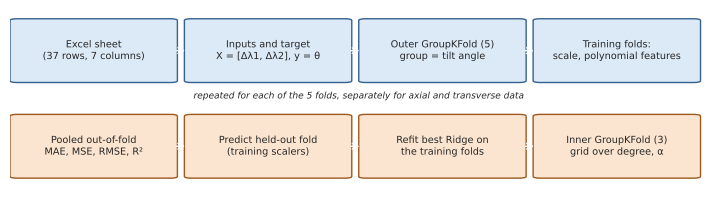

report built at figure scale 1.0: 7 pages


report built at figure scale 0.9: 6 pages
DONE -> results/FBG_Lab6_Report.pdf | tables in results/tables | figures in results/figures


In [15]:
# %% 13. BUILD THE PDF REPORT (6 pages max; figures shrink automatically if needed)
try:
    import reportlab
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "reportlab"])
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import cm
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.pdfmetrics import registerFontFamily
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether
from PIL import Image as PILImage
from matplotlib.patches import FancyBboxPatch

fd = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")
for n, f in (("DV", "DejaVuSans.ttf"), ("DVB", "DejaVuSans-Bold.ttf"), ("DVI", "DejaVuSans-Oblique.ttf")):
    pdfmetrics.registerFont(TTFont(n, os.path.join(fd, f)))
registerFontFamily("DV", normal="DV", bold="DVB", italic="DVI", boldItalic="DVB")

def draw_pipeline():
    fig, ax = plt.subplots(figsize=(9, 2.3)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    top = ["Excel sheet\n(37 rows, 7 columns)", "Inputs and target\nX = [Δλ1, Δλ2], y = θ", "Outer GroupKFold (5)\ngroup = tilt angle", "Training folds:\nscale, polynomial features"]
    bot = ["Pooled out-of-fold\nMAE, MSE, RMSE, R²", "Predict held-out fold\n(training scalers)", "Refit best Ridge on\nthe training folds", "Inner GroupKFold (3)\ngrid over degree, α"]
    xs = [0.01, 0.26, 0.51, 0.76]; w, h = 0.22, 0.34
    for i, t in enumerate(top):
        ax.add_patch(FancyBboxPatch((xs[i], 0.60), w, h, boxstyle="round,pad=0.01", fc="#DCE9F7", ec="#35618f"))
        ax.text(xs[i] + w / 2, 0.77, t, ha="center", va="center", fontsize=7)
        if i < 3: ax.annotate("", (xs[i + 1] - 0.005, 0.77), (xs[i] + w + 0.005, 0.77), arrowprops=dict(arrowstyle="->"))
    for i, t in enumerate(bot):
        ax.add_patch(FancyBboxPatch((xs[i], 0.06), w, h, boxstyle="round,pad=0.01", fc="#FBE5D0", ec="#9c5a20"))
        ax.text(xs[i] + w / 2, 0.23, t, ha="center", va="center", fontsize=7)
        if i < 3: ax.annotate("", (xs[i] + w + 0.005, 0.23), (xs[i + 1] - 0.005, 0.23), arrowprops=dict(arrowstyle="<-"))
    ax.annotate("", (xs[3] + w / 2, 0.41), (xs[3] + w / 2, 0.59), arrowprops=dict(arrowstyle="<-"))
    ax.text(0.5, 0.5, "repeated for each of the 5 folds, separately for axial and transverse data", ha="center", fontsize=6.5, style="italic")
    save_fig(fig, "fig_pipeline")
draw_pipeline()

def build_report(scale, path):
    S = lambda **k: ParagraphStyle("s", fontName=k.pop("fontName", "DV"), **k)
    body = S(fontSize=7.6, leading=9.6, spaceAfter=2); h1 = S(fontName="DVB", fontSize=9.5, leading=11, spaceBefore=4, spaceAfter=2, textColor=colors.HexColor("#1f3b66"))
    cap = S(fontSize=6.6, leading=8, textColor=colors.HexColor("#444444"), spaceAfter=3)
    title = S(fontName="DVB", fontSize=12, leading=14.5, alignment=1, spaceAfter=2); sub = S(fontSize=8, alignment=1, spaceAfter=4)
    W = A4[0] - 2.4 * cm
    P = lambda t, st=body: Paragraph(t, st)

    def img(name, c, w_frac=1.0):
        iw, ih = PILImage.open(FIGS[name]).size; w = W * w_frac * scale
        return [Image(FIGS[name], width=w, height=w * ih / iw), P(c, cap)]

    def tbl(df, cols, hdr, widths, fmts, hl="RMSE", fs=6.4, best="min"):
        data = [hdr]
        for idx, r in df.iterrows():
            data.append([str(idx)] + [fmts[i](r[c]) for i, c in enumerate(cols)])
        st = [("FONT", (0, 0), (-1, -1), "DV", fs), ("FONT", (0, 0), (-1, 0), "DVB", fs), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#d9e2f3")),
              ("GRID", (0, 0), (-1, -1), 0.25, colors.grey), ("TOPPADDING", (0, 0), (-1, -1), 1), ("BOTTOMPADDING", (0, 0), (-1, -1), 1),
              ("LEFTPADDING", (0, 0), (-1, -1), 2), ("RIGHTPADDING", (0, 0), (-1, -1), 2), ("ALIGN", (1, 0), (-1, -1), "RIGHT")]
        if hl in cols:
            k = list(df.index).index(df[hl].idxmin() if best == "min" else df[hl].idxmax()) + 1
            st += [("BACKGROUND", (0, k), (-1, k), colors.HexColor("#d8f0d2")), ("FONT", (0, k), (-1, k), "DVB", fs)]
        t = Table(data, colWidths=[x * cm for x in widths]); t.setStyle(TableStyle(st)); return t

    f4 = lambda x: f"{x:.4f}"; f2 = lambda x: f"{x:.2f}"
    fl = [P("Implementation and Comparative Performance Analysis of Traditional Statistical and Conventional Machine Learning Regression Models for FBG-Based Tilt Angle Prediction", title),
          P(f"Machine Learning Laboratory, Experiment 06 (13 Oct 2026) | {STUDENT_NAME} | {ROLL_NO}<br/>Code: {CODE_URL}", sub)]
    fl += [P("1. Methodology", h1), P(METHOD)]
    fl += img("fig_pipeline", "Fig. 1 End-to-end process, drawn for Ridge regression (the other models use the same loop).")
    fl += [P(ALGO)]

    fl += [P("2. Results (grouped 5-fold CV, best RMSE highlighted)", h1)]
    cols = ["MAE", "MSE", "RMSE", "R2", "TrainTime"]; hdr = ["Model", "MAE", "MSE", "RMSE", "R²", "Train (s)"]
    cell = []
    for ds in D:
        cell.append([P(f"<b>Table {1 if ds == 'Axial' else 2}.</b> {ds} tilt (errors in degrees)", cap), tbl(R[ds], cols, hdr, [2.35, 1.2, 1.6, 1.2, 1.15, 1.3], [f4, f2, f4, f4, f4])])
    t = Table([cell], colWidths=[W / 2, W / 2]); t.setStyle(TableStyle([("VALIGN", (0, 0), (-1, -1), "TOP"), ("LEFTPADDING", (0, 0), (-1, -1), 0)])); fl += [t, Spacer(1, 2), P(RES_NOTE)]

    fl += [P("3. Hyper-parameters and feature analysis", h1)]
    hp = HPT.copy(); hp.index = hp.Model + ", " + hp.Setting
    cols = ["Axi MAE", "Axi RMSE", "Axi R2", "Tra MAE", "Tra RMSE", "Tra R2"]
    fl += [P("<b>Table 3.</b> Hyper-parameter study with fixed values (grouped 5-fold CV, inputs Δλ1 and Δλ2, signed θ). The Ridge/Lasso/Elastic Net rows use cubic features and show what the penalty strength does.", cap),
           tbl(hp, cols, ["Configuration", "Axial MAE", "Axial RMSE", "Axial R²", "Transv. MAE", "Transv. RMSE", "Transv. R²"], [5.2, 2.0, 2.0, 2.0, 2.2, 2.2, 2.2], [f4] * 6, hl="Axi RMSE", fs=6)]
    sel = pd.DataFrame({"Axial": R["Axial"].Params, "Transverse": R["Transverse"].Params})
    data = [["Model", "Chosen by the inner CV, axial", "Chosen by the inner CV, transverse"]] + [[n, sel.loc[n, "Axial"], sel.loc[n, "Transverse"]] for n in sel.index if sel.loc[n].ne("-").any()]
    ts = Table(data, colWidths=[3 * cm, 7 * cm, 7.4 * cm]); ts.setStyle(TableStyle([("FONT", (0, 0), (-1, -1), "DV", 6), ("FONT", (0, 0), (-1, 0), "DVB", 6), ("GRID", (0, 0), (-1, -1), .25, colors.grey),
                                                                                     ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#d9e2f3")), ("TOPPADDING", (0, 0), (-1, -1), 1), ("BOTTOMPADDING", (0, 0), (-1, -1), 1)]))
    fl += [P("<b>Table 4.</b> Hyper-parameters picked in the main nested run (most frequent choice over the 5 outer folds).", cap), ts, Spacer(1, 3)]
    cp = list(FEAT.columns)
    fl += [P("<b>Table 5.</b> Feature sets F1 to F4: RMSE in degrees for multiple linear regression (MLR), degree-2 polynomial and random forest (RF).", cap),
           tbl(FEAT, cp, ["Feature set"] + [c.replace(" RMSE", "") for c in cp], [3.0] + [2.2] * 6, [f2] * 6, hl="none", fs=6)]
    cr = CORR[["Axial r", "Transverse r"]].copy(); cr["Transverse r with |θ|"] = TCCORR["r with |theta|"].values
    fl += [Spacer(1, 3), P("<b>Table 6.</b> Pearson correlation of each feature with θ (and, for the transverse data, with |θ|).", cap),
           tbl(cr, list(cr.columns), ["Feature", "Axial r", "Transverse r", "Transverse r with |θ|"], [3, 2.4, 2.4, 3.4], [f4] * 3, hl="none", fs=6)]

    fl += [P("4. Figures", h1)]
    order = [("fig2_rmse", "Fig. 2 Model-wise RMSE (blue = statistical, orange = ML)."), ("fig1_mae", "Fig. 3 Model-wise MAE."), ("fig3_r2", "Fig. 4 Model-wise R²."),
             ("fig7_training_time", "Fig. 5 Training time per fold (log scale)."), ("fig4_avp_best_statistical", "Fig. 6 Actual vs predicted angle, best statistical model."),
             ("fig5_avp_best_ml", "Fig. 7 Actual vs predicted angle, best conventional ML model."), ("fig6_residuals", "Fig. 8 Residual plots of the two selected models."),
             ("fig_task2_scatter", "Fig. 9 FBG readings and wavelength changes against tilt angle."), ("fig_task2_heatmap", "Fig. 10 Correlation heatmaps."), ("fig_task2_boxplots", "Fig. 11 Box plots (no outliers by the 1.5 IQR rule)."),
             ("fig_task2_scaling", "Fig. 12 Inputs before and after StandardScaler and MinMaxScaler (fitted on a training fold)."), ("fig_task1_distributions", "Fig. 13 Distribution of tilt angle and wavelength changes.")]
    for n, c in order:
        fl.append(KeepTogether(img(n, c)))

    fl += [P("5. Advanced task C: signed and absolute tilt (transverse data)", h1)]
    tc = TC[["Signed_RMSE", "Signed_R2", "Abs_RMSE", "Abs_R2"]]
    fl += [KeepTogether([P("<b>Table 7.</b> Same models and CV folds, target θ against target |θ| (errors in degrees).", cap),
           tbl(tc, list(tc.columns), ["Model", "θ: RMSE", "θ: R²", "|θ|: RMSE", "|θ|: R²"], [3.2, 2.3, 2.3, 2.3, 2.3], [f2, f4, f2, f4], hl="Abs_RMSE", fs=6.4)]), Spacer(1, 3)]
    fl += img("fig_advC_signed_vs_abs", "Fig. 14 Best model for the signed target (left) and for the absolute target (right), out-of-fold predictions.")
    fl += [P(TASKC_TXT)]

    fl += [P("6. Discussion and conclusions", h1)] + [P(f"<b>{q}</b> {a}") for q, a in DISC]
    fl += [P(f"All numbers come from running the code (seed {SEED}). Code: {CODE_URL}")]

    doc = SimpleDocTemplate(path, pagesize=A4, leftMargin=1.2 * cm, rightMargin=1.2 * cm, topMargin=1.0 * cm, bottomMargin=1.0 * cm)
    doc.build(fl); return doc.page

pdf = f"{OUT}/FBG_Lab6_Report.pdf"
for sc in (1.0, 0.9, 0.8, 0.72, 0.65, 0.58, 0.52):
    pages = build_report(sc, pdf)
    print(f"report built at figure scale {sc}: {pages} pages")
    if pages <= 6:
        break
print("DONE ->", pdf, "| tables in", TAB_DIR, "| figures in", FIG_DIR)
if pages > 6:
    print("WARNING: still more than 6 pages - remove Fig. 12 / Fig. 13 from the 'order' list")